# Targeted model poisoning on Adult Census (IID)

Replicates the Adult Census experiment of Bhagoji et al., *Analyzing Federated Learning through an Adversarial Lens* (ICML 2019), on the hand-written network from `FL_mlp_iid.ipynb`. Settings follow the paper's code (github.com/inspire-group/ModelPoisoning):
- **Data:** UCI Adult with missing rows dropped, one-hot encoded and MinMax-scaled (104 features); the first 30,160 training rows go to 10 equal IID shards.
- **Model:** 104-256-2 with Dropout(0.5).
- **Training:** Adam at lr 1e-3, 5 local epochs, batch size 100, all 10 clients every round, 40 rounds.
- **Attacker:** the last client wants one test record classified as the wrong class. By default that's a class-0 (≤50K) record pushed to class 1; `target_true_class = 1` flips a >50K record instead. `attack_type` picks the strategy, each following the paper's code:
  - `baseline`: explicit boosting — train only on the target until its loss < 1e-6, then boost the update ×10.
  - `stealthy`: each step applies `own-data step + 20 × target step`, with a distance penalty to its own benign model.
  - `altmin`: alternating minimization — 10 own-data steps (with the penalty), then 1 target step boosted ×20, for 10 epochs.
- **Aggregation:** `aggregation` picks FedAvg, Krum or coordinate-wise median (paper Sec. 4).
- **Stealth metrics** (paper Sec. 2.3) are logged every round:
  - the accuracy check: the attacker's model alone vs. the aggregate of the others, flagged if more than 10% lower;
  - the L2 distance ranges between updates.

## What we did and found

**What we did:** reproduced the Adult Census experiments of Bhagoji et al. (ICML 2019) on our hand-written network. One of the 10 clients tries to make the global model misclassify one chosen record (≤50K → >50K) while keeping the model accurate otherwise.

| Run (40 rounds, seed 42) | Target misclassified | Final test acc | Attacker passes accuracy check |
|---|---|---|---|
| No attack | 0/40 | 84.7% | — |
| Baseline boosting, FedAvg | 40/40 | 77.6% | 0/40 |
| Stealthy, FedAvg | 28/40 | 84.5% | 21/40 |
| Alternating min., FedAvg | 29/40 | 84.4% | 40/40 |
| Alternating min. vs Krum | 0/40 | 83.9% | 40/40 |
| Baseline vs coordinate median | 0/40 | 84.6% | 0/40 |

- **Matches the paper:** boosting flips the target but drops accuracy to ~80%, while the stealthy attacks flip it and keep ~84%.
- **Doesn't match:** in the paper, the stealthy updates look benign by distance and beat Krum and median. Here they sit ~2× farther from the benign updates, so Krum never picks the attacker and neither defense is beaten. The paper shows those results on Fashion-MNIST, not Adult.
- **Where the paper's text and code differ, we followed its code**, because the code produced its numbers. For example, the attacker trains on the target until its loss is below 1e-6, not for 5 steps.
- **Across 5 seeds and both label directions** (60 runs):
  - Boosting always flips the target in every round. Accuracy drops to 74.6 ± 4.8% pushing ≤50K → >50K, and to 79.7 ± 2.2% the other way, which is closer to the paper's ~80%.
  - The stealthy attacks keep ~84% accuracy, but whether they succeed depends on the target. They flipped 3 of 5 targets pushing ≤50K → >50K, and 2–3 of 4 the other way. Records the clean model is very sure about resist.
  - Krum never picked the attacker, and no target flipped under Krum or the median in any run. So the mismatch with the paper isn't a one-run fluke.
  - The data is 75% ≤50K, so a model that only predicts ≤50K already scores ~75%. Pushing toward that class, even plain boosting passes the 10% accuracy check every round.
  - One >50K target (seed 4) was already misclassified by the clean model, so it's left out of these counts.

In [ ]:
import torch
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import os
import random
import copy

# For reproducibility
np.random.seed(42)
random.seed(42)        # client selection
torch.manual_seed(42)  # weight init, dropout

# Device configuration (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Settings from the paper's code (github.com/inspire-group/ModelPoisoning, census run)
learning_rate = 0.001  # Adam, same for every client
batch_size = 100
epochs = 5             # local epochs per round
num_clients = 10
federated_rounds = 40
selection_factor = 1.0 # every client trains every round

# Attack: one malicious client (the paper uses the last one)
attack = True
attack_type = "baseline"  # "baseline" (explicit boosting), "stealthy" or "altmin" (alternating minimization)
malicious_client = num_clients - 1
target_true_class = 0  # the target record's real class: 0 (<=50K, pushed to >50K) or 1 (>50K, pushed to <=50K)

aggregation = "fedavg"  # "fedavg", "krum" or "coordinate_median"

# Boost factors from the paper. With FedAvg (Census, tech report Fig. 8): x10 for baseline, x20 for the stealthy
# attacks. Against Krum it uses altmin with x2, against the median baseline with x1 (Sec. 4, Fashion-MNIST runs)
if aggregation == "krum":
    boost_factor = 2
elif aggregation == "coordinate_median":
    boost_factor = 1
else:
    boost_factor = 10 if attack_type == "baseline" else 20
rho = 1e-4             # weight of the distance penalty to the attacker's own benign model
mal_epochs = 10 if attack_type == "altmin" else epochs  # attacker's training epochs
ls = 10                # altmin: own-data steps between target steps

In [ ]:
# UCI Adult (Census): drop rows with missing values, one-hot the 8 categorical columns and
# MinMax-scale, which gives the same 104 features as the paper's code
adult_columns = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
                 "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
                 "hours-per-week", "native-country", "income"]

def load_adult(path, skiprows=0):
    df = pd.read_csv(path, names=adult_columns, skipinitialspace=True, na_values="?", skiprows=skiprows).dropna()
    labels = (df["income"].str.rstrip(".") == ">50K").astype(np.int64).to_numpy()  # test labels end with "."
    return df.drop(columns="income"), labels

train_df, y_train_all = load_adult('./data/adult/adult.data')
test_df, y_test = load_adult('./data/adult/adult.test', skiprows=1)  # first line of adult.test is not a record

categorical = train_df.select_dtypes(exclude="number").columns
X_train_df = pd.get_dummies(train_df, columns=categorical, dtype=float)
X_test_df = pd.get_dummies(test_df, columns=categorical, dtype=float).reindex(columns=X_train_df.columns, fill_value=0.0)

scaler = MinMaxScaler()
X_train_all = scaler.fit_transform(X_train_df).astype(np.float32)
X_test = scaler.transform(X_test_df).astype(np.float32)

# The paper's code keeps the first 30160 training rows, so 10 clients get 3016 each
X_train_all, y_train_all = X_train_all[:30160], y_train_all[:30160]

print(f"Train {X_train_all.shape}, test {X_test.shape}, class-1 share in train {y_train_all.mean():.3f}")

Train (30160, 104), test (15060, 104), class-1 share in train 0.249


In [ ]:
# IID split as in the paper's code: shuffle once, then cut into num_clients equal shards
def iid_split(X, y, num_clients):
    perm = np.random.permutation(len(X))
    return list(zip(np.split(X[perm], num_clients), np.split(y[perm], num_clients)))

In [ ]:
class Dense:
    def __init__(self, input_size, output_size, lr=0.005, beta1=0.9, beta2=0.999, epsilon=1e-8, device='cpu'):
        self.device = device
        self.weights = torch.randn(input_size, output_size, device=device) * np.sqrt(2.0 / input_size)
        self.bias = torch.zeros(1, output_size, device=device)
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon
        self.m_w, self.v_w = torch.zeros_like(self.weights), torch.zeros_like(self.weights)
        self.m_b, self.v_b = torch.zeros_like(self.bias), torch.zeros_like(self.bias)
        self.t = 0  # Time step
        # Optional penalty prox_rho * 0.5 * ||weights - prox_ref||^2 (off unless an attacker sets it)
        self.prox_rho = 0.0
        self.prox_ref = None

    def forward(self, X):
        self.input = X
        return torch.mm(X, self.weights) + self.bias  # Matrix multiplication (for GPU support)

    def backward(self, d_output):
        prev_weights = self.weights
        d_weights = torch.mm(self.input.T, d_output)
        d_bias = torch.sum(d_output, axis=0, keepdims=True)
        if self.prox_rho:
            d_weights = d_weights + self.prox_rho * (self.weights - self.prox_ref)

        # Update Adam time step
        self.t += 1

        # Moving averages of gradients for weights
        self.m_w = self.beta1 * self.m_w + (1 - self.beta1) * d_weights
        self.v_w = self.beta2 * self.v_w + (1 - self.beta2) * (d_weights ** 2)

        # Moving averages of gradients for biases
        self.m_b = self.beta1 * self.m_b + (1 - self.beta1) * d_bias
        self.v_b = self.beta2 * self.v_b + (1 - self.beta2) * (d_bias ** 2)

        # Bias correction
        m_w_hat = self.m_w / (1 - self.beta1 ** self.t)
        v_w_hat = self.v_w / (1 - self.beta2 ** self.t)
        m_b_hat = self.m_b / (1 - self.beta1 ** self.t)
        v_b_hat = self.v_b / (1 - self.beta2 ** self.t)

        self.weights -= self.lr * m_w_hat / (torch.sqrt(v_w_hat) + self.epsilon)
        self.bias -= self.lr * m_b_hat / (torch.sqrt(v_b_hat) + self.epsilon)

        # Return the gradient for the previous layer
        return torch.mm(d_output, prev_weights.T)


class ReLU:
    def forward(self, X):
        self.input = X
        return torch.maximum(torch.tensor(0.0, device=X.device), X)

    def backward(self, d_output):
        return d_output * (self.input > 0)


In [ ]:
class Dropout:
    def __init__(self, rate=0.2):
        self.rate = rate

    def forward(self, X, training=True):
        if training:
            self.mask = (torch.rand(*X.shape, device=X.device) > self.rate) / (1 - self.rate)
            return X * self.mask
        else:
            return X

    def backward(self, d_output):
        return d_output * self.mask

In [ ]:
class BatchNorm:
    def __init__(self, input_dim, lr=0.005, epsilon=1e-5, momentum=0.9, device='cpu'):
        self.device = device
        self.lr = lr
        self.epsilon = epsilon
        self.momentum = momentum
        self.gamma = torch.ones((1, input_dim), device=device)
        self.beta = torch.zeros((1, input_dim), device=device)
        self.running_mean = torch.zeros((1, input_dim), device=device)
        self.running_var = torch.ones((1, input_dim), device=device)

    def forward(self, X, training=True):
        if training:
            batch_mean = torch.mean(X, axis=0, keepdims=True)
            batch_var = torch.var(X, axis=0, keepdims=True)

            self.X_centered = X - batch_mean
            self.stddev_inv = 1. / torch.sqrt(batch_var + self.epsilon)
            X_norm = self.X_centered * self.stddev_inv

            out = self.gamma * X_norm + self.beta  # to give the model flexibility to cancel out normalization
            self.running_mean = self.momentum * self.running_mean + (1 - self.momentum) * batch_mean
            self.running_var = self.momentum * self.running_var + (1 - self.momentum) * batch_var
        else:
            X_norm = (X - self.running_mean) / torch.sqrt(self.running_var + self.epsilon)
            out = self.gamma * X_norm + self.beta

        return out

    def backward(self, d_output):
        n_samples = d_output.shape[0]

        d_gamma = torch.sum(d_output * self.X_centered * self.stddev_inv, axis=0, keepdims=True)
        d_beta = torch.sum(d_output, axis=0, keepdims=True)

        d_X_norm = d_output * self.gamma
        d_var = torch.sum(d_X_norm * self.X_centered * -0.5 * self.stddev_inv**3, axis=0)
        d_mean = torch.sum(d_X_norm * -self.stddev_inv, axis=0) + d_var * torch.mean(-2. * self.X_centered, axis=0)

        d_input = d_X_norm * self.stddev_inv + d_var * 2 * self.X_centered / n_samples + d_mean / n_samples
        self.gamma -= self.lr * d_gamma
        self.beta -= self.lr * d_beta

        return d_input



In [ ]:
class Softmax:
    def forward(self, x):
        x_max = torch.max(x, axis=1, keepdims=True).values
        exp_values = torch.exp(x - x_max)
        sum_exp_values = torch.sum(exp_values, axis=1, keepdims=True)
        epsilon = 1e-10
        probabilities = exp_values / (sum_exp_values + epsilon)
        return probabilities

    def backward(self, output, y):
        n_samples = y.shape[0]
        grad = output.clone()
        grad[range(n_samples), y] -= 1
        grad = grad / n_samples
        return grad

def cross_entropy_loss(predictions, labels):
    n_samples = labels.shape[0]
    logp = -torch.log(predictions[range(n_samples), labels] + 1e-15)
    loss = torch.sum(logp) / n_samples
    return loss


In [ ]:
class NeuralNetwork:
    def __init__(self, input_dim, num_classes, lr=0.001, device='cpu'):
        self.input_dim = input_dim
        self.num_classes= num_classes
        self.device = device
        self.softmax = Softmax()
        # The paper's census model as it actually runs: census_model_1 builds its second Dense(256)
        # on the input again, so the first hidden layer is discarded and the model is 104-256-2
        self.layers = [
            Dense(input_dim, 256, lr, device=device),
            ReLU(),
            Dropout(0.5),
            Dense(256, num_classes, lr, device=device)
        ]

    def forward(self, X, training=True):
        X = X.to(self.device)
        for layer in self.layers:
            if isinstance(layer, (BatchNorm, Dropout)):
                X = layer.forward(X, training=training)
            else:
                X = layer.forward(X)

        return self.softmax.forward(X)

    def backward(self, d_output):
        for layer in reversed(self.layers):
            d_output = layer.backward(d_output)

    #def train(self, X_train, y_train, X_val, y_val, epochs, batch_size):

    def train(self, X_train, y_train, epochs, batch_size):

        n_samples = X_train.shape[0]
        training_loss, val_loss, training_acc, val_acc, val_f1 = [], [], [], [], []

        for epoch in range(epochs):
            losses = []
            # disable=True: the bar re-renders on every run and churns the notebook diff
            for i in tqdm(range(0, n_samples, batch_size), disable=True):
                x_batch = torch.tensor(X_train[i:i+batch_size], dtype=torch.float32).to(self.device)
                y_batch = torch.tensor(y_train[i:i+batch_size], dtype=torch.long).to(self.device)

                # Forward pass
                output = self.forward(x_batch, training=True)

                # Loss calculation
                loss = cross_entropy_loss(output, y_batch)
                losses.append(loss)

                # Backward pass
                d_output = self.softmax.backward(output, y_batch)
                self.backward(d_output)

            # Training Loss & Accuracy
            train_preds = self.predict(X_train)
            train_accuracy = accuracy_score(y_train, train_preds)
            losses = [loss.item() if isinstance(loss, torch.Tensor) else loss for loss in losses]
            training_loss.append(np.mean(losses))
            # training_loss.append(np.mean(losses.cpu().numpy()))
            training_acc.append(train_accuracy)

            # Validation Loss & Accuracy
            # val_preds = self.predict(X_val)
            # val_accuracy = accuracy_score(y_val, val_preds)
            # val_f1_score = f1_score(y_val, val_preds, average="macro")
            # val_loss_epoch = cross_entropy_loss(self.forward(torch.tensor(X_val, dtype=torch.float32).to(self.device), training=False), torch.tensor(y_val, dtype=torch.long).to(self.device))

            # val_loss.append(val_loss_epoch.item())
            # val_acc.append(val_accuracy)
            # val_f1.append(val_f1_score)

            # print(f"Epoch {epoch+1}/{epochs}, Train Loss: {training_loss[-1]:.4f}, "
            #       f"Val Loss: {val_loss[-1]:.4f}, Train Acc: {train_accuracy:.4f}, "
            #       f"Val Acc: {val_accuracy:.4f}, Val F1: {val_f1_score:.4f}")

            print(f"Epoch {epoch+1}/{epochs}, Train Loss: {training_loss[-1]:.4f}, "
                  f"Train Acc: {train_accuracy:.4f}, ")




        # return training_loss, val_loss, training_acc, val_acc, val_f1
        return training_loss, training_acc

    def probabilities(self, X):
        X_tensor = torch.tensor(X, dtype=torch.float32).to(self.device)
        return self.forward(X_tensor, training=False).cpu().numpy()  # Move to CPU for numpy conversion

    def predict(self, X_test):
        return np.argmax(self.probabilities(X_test), axis=1)

    def evaluate(self, X_test, y_test):
        return accuracy_score(y_test, self.predict(X_test))


In [ ]:
# Weight matrices only (no biases), flattened: what the paper's Krum and distance statistics use
def flatten_weights(params):
    keys = sorted((k for k in params if k.endswith("_weights")), key=lambda k: int(k.split("_")[1]))
    return torch.cat([params[k].flatten() for k in keys])


class Server:

    def __init__(self ,model, X_test, y_test, aggregation="fedavg", device= "cuda"):
        self.global_model = model
        self.clientList = [] #List of all clients registered
        self.selectedClientList = [] #List of clients selected in a specific round
        self.markedClientList = [] #List of clients marked vulnerable( Not yet used )
        self.device = device
        self.X_test = X_test
        self.y_test = y_test
        self.aggregation = aggregation
        self.krum_choice = None

    # Register Clients

    def register(self, clients):
        self.clientList.append(clients)
        print("Registering client")


    # Select Clients in each round

    def select(self, clientMap):

        client_id, client = clientMap
        self.selectedClientList.append(clientMap)
        print("Selecting client ", client_id)

    # Reset the server in each round

    def reset(self):
        self.selectedClientList = []

    # Aggregrate updates

    def aggregate(self, localUpdates, client_sizes):

        print("Getting aggregated by server")

        if self.aggregation == "krum":
            return self.krum(localUpdates)
        if self.aggregation == "coordinate_median":
            return self.coordinate_median(localUpdates)
        if self.aggregation != "fedavg":
            raise ValueError(f"aggregation must be 'fedavg', 'krum' or 'coordinate_median', got {self.aggregation!r}")

        # FedAvg weighted by each client's local sample count (n_k/n), not a plain mean
        total_samples = sum(client_sizes)
        client_weights = torch.tensor([size / total_samples for size in client_sizes], device=self.device)

        aggregated_params = {}
        for key in localUpdates[0].keys():
            stacked = torch.stack([update[key].float().to(self.device) for update in localUpdates], dim=0)
            weight_shape = [len(client_sizes)] + [1] * (stacked.dim() - 1)
            aggregated_params[key] = (stacked * client_weights.view(weight_shape)).sum(dim=0)

        return aggregated_params


    # Krum as in the paper's code: score each update by the sum of its (unsquared) L2 distances to its
    # n - f - 2 closest updates (f = 1), on weight matrices only; the lowest score is applied as is
    def krum(self, localUpdates, f=1):
        n = len(localUpdates)
        flat = torch.stack([flatten_weights(u) for u in localUpdates])
        dists = torch.cdist(flat, flat)
        scores = torch.stack([torch.sort(torch.cat([dists[i, :i], dists[i, i + 1:]])).values[:n - f - 2].sum()
                              for i in range(n)])
        chosen = int(torch.argmin(scores))
        self.krum_choice = self.selectedClientList[chosen][0]
        print(f"Krum selected client {self.krum_choice}")
        return localUpdates[chosen]

    # Coordinate-wise median; quantile(0.5) averages the two middle values for an even count, like np.median
    def coordinate_median(self, localUpdates):
        return {key: torch.quantile(torch.stack([u[key] for u in localUpdates]), 0.5, dim=0)
                for key in localUpdates[0]}

    def accuracy_of(self, params):
        model = copy.deepcopy(self.global_model)
        for i, layer in enumerate(model.layers):
            if isinstance(layer, Dense):
                layer.weights = params[f"layer_{i}_weights"].clone()
                layer.bias = params[f"layer_{i}_bias"].clone()
        return model.evaluate(self.X_test, self.y_test)

    # The paper's stealth metrics (Sec. 2.3), measured for analysis; the server itself does not know
    # which client is malicious. Updates are compared as sent (the boosted one for the attacker).
    def stealth_metrics(self, localUpdates, malicious_id, gamma=0.10):
        ids = [client_id for client_id, _ in self.selectedClientList]
        if malicious_id not in ids:
            return None
        m = ids.index(malicious_id)
        benign = [u for k, u in enumerate(localUpdates) if k != m]

        # Accuracy check: the malicious model alone vs. the average of all the other updates
        acc_mal = self.accuracy_of(localUpdates[m])
        acc_others = self.accuracy_of({key: torch.stack([u[key] for u in benign]).mean(dim=0) for key in benign[0]})

        # Weight update statistics (the paper's l2dist_calc.py): benign pairwise L2 distances vs.
        # distances from the malicious update to each benign one, on weight matrices only
        flat = torch.stack([flatten_weights(u) for u in localUpdates])
        dists = torch.cdist(flat, flat)
        benign_idx = [k for k in range(len(localUpdates)) if k != m]
        benign_pairs = torch.stack([dists[a, b] for x, a in enumerate(benign_idx) for b in benign_idx[x + 1:]])
        mal_to_benign = dists[m, benign_idx]

        metrics = {
            "acc_mal": acc_mal, "acc_others": acc_others,
            "passes_accuracy_check": acc_others - acc_mal <= gamma,
            "benign_range": (benign_pairs.min().item(), benign_pairs.max().item()),
            "mal_range": (mal_to_benign.min().item(), mal_to_benign.max().item()),
        }
        metrics["inside_benign_range"] = (metrics["mal_range"][0] >= metrics["benign_range"][0]
                                          and metrics["mal_range"][1] <= metrics["benign_range"][1])

        # Weight-update values (weight matrices only) of the attacker and one benign client, for the
        # paper's histograms; the global model still holds last round's weights here
        current = flatten_weights({f"layer_{i}_weights": l.weights
                                   for i, l in enumerate(self.global_model.layers) if isinstance(l, Dense)})
        metrics["mal_delta"] = (flatten_weights(localUpdates[m]) - current).cpu().numpy()
        metrics["benign_delta"] = (flatten_weights(benign[0]) - current).cpu().numpy()
        print(f"Stealth: acc(mal) {acc_mal:.4f} vs acc(others) {acc_others:.4f} -> "
              f"{'passes' if metrics['passes_accuracy_check'] else 'FLAGGED by'} accuracy check; "
              f"L2 range benign [{metrics['benign_range'][0]:.3f}, {metrics['benign_range'][1]:.3f}], "
              f"malicious [{metrics['mal_range'][0]:.3f}, {metrics['mal_range'][1]:.3f}]")
        return metrics

    # Update global model with aggregrated parameters


    def update_global_model(self, localUpdates, client_sizes):

        aggregated_params = self.aggregate(localUpdates, client_sizes)

        # Layer by layer update weight to model self.global_model.
        for i, layer in enumerate(self.global_model.layers):
            if isinstance(layer, Dense):
                layer.weights = aggregated_params[f"layer_{i}_weights"]
                layer.bias = aggregated_params[f"layer_{i}_bias"]
            elif isinstance(layer, BatchNorm):
                layer.gamma = aggregated_params[f"layer_{i}_gamma"]
                layer.beta = aggregated_params[f"layer_{i}_beta"]
                layer.running_mean = aggregated_params[f"layer_{i}_running_mean"]
                layer.running_var = aggregated_params[f"layer_{i}_running_var"]


        print("Done Aggregating")

    # Test accuracy plus the global model's view of the attacker's target record
    def evaluate(self, target_x, target_label):
        test_accuracy = self.global_model.evaluate(self.X_test, self.y_test)
        probs = self.global_model.probabilities(target_x)[0]
        print(f"Test Acc: {test_accuracy:.4f}, target predicted as class {probs.argmax()} "
              f"(confidence in target label {target_label}: {probs[target_label]:.4f})")
        return test_accuracy, probs[target_label], probs.argmax()

    # Distribute updated model to clients

    def distribute_global_model(self):
        for client in self.clientList:
            client.receive_model(self.global_model)

In [ ]:

# Federated Learning Client Class
class Client:
    def __init__(self, model, X_train, y_train, epochs, batch_size, device='cpu'):
        self.X_train = X_train
        self.y_train = y_train
        self.num_samples = len(y_train)
        self.epochs = epochs
        self.batch_size = batch_size
        # Private copy: sharing one model object makes every client train the same tensors
        self.model = copy.deepcopy(model)
        self.device = device


    def train(self):
        train_loss, train_acc = self.model.train( self.X_train, self.y_train, self.epochs, self.batch_size )

    def get_parameters(self):
        weights = {}
        # clone(): layers update weights in-place, so an un-cloned snapshot would keep changing
        for i, layer in enumerate(self.model.layers):
            if isinstance(layer, Dense):
                weights[f"layer_{i}_weights"] = layer.weights.clone()
                weights[f"layer_{i}_bias"] = layer.bias.clone()
            elif isinstance(layer, BatchNorm):
                weights[f"layer_{i}_gamma"] = layer.gamma.clone()
                weights[f"layer_{i}_beta"] = layer.beta.clone()
                weights[f"layer_{i}_running_mean"] = layer.running_mean.clone()
                weights[f"layer_{i}_running_var"] = layer.running_var.clone()


        return weights

    def receive_model(self,global_model):
        self.model=copy.deepcopy(global_model)


In [ ]:
# Malicious client: the paper's basic targeted model poisoning with explicit boosting
# ('converge' strategy in its code). It ignores its own data shard.
class BoostingClient(Client):
    def __init__(self, model, X_train, y_train, epochs, batch_size, target_x, target_label, boost_factor,
                 device='cpu', min_steps=5, max_steps=10000):
        super().__init__(model, X_train, y_train, epochs, batch_size, device)
        self.target_x = torch.tensor(target_x, dtype=torch.float32)
        self.target_y = torch.tensor([target_label], dtype=torch.long)
        self.boost_factor = boost_factor
        self.min_steps = min_steps
        self.max_steps = max_steps  # the paper's loop has no cap; this stops a run that never converges

    def train(self):
        start_weights = self.get_parameters()

        # Train only on the target with the wrong label until its loss < 1e-6, checked every
        # 100 steps as in the paper's code (and at least min_steps steps)
        step, loss_val = 0, float('inf')
        while (loss_val > 1e-6 or step < self.min_steps) and step < self.max_steps:
            output = self.model.forward(self.target_x, training=True)
            self.model.backward(self.model.softmax.backward(output, self.target_y))
            if step % 100 == 0:
                loss_val = cross_entropy_loss(self.model.forward(self.target_x, training=True), self.target_y).item()
            step += 1

        # Explicit boosting: send start + boost * delta, so the 1/num_clients averaging weight
        # still applies the full malicious change
        for i, layer in enumerate(self.model.layers):
            if isinstance(layer, Dense):
                w0, b0 = start_weights[f"layer_{i}_weights"], start_weights[f"layer_{i}_bias"]
                layer.weights = w0 + self.boost_factor * (layer.weights - w0)
                layer.bias = b0 + self.boost_factor * (layer.bias - b0)

        print(f"Boosting client: {step} steps on the target, target loss {loss_val:.2e}, boosted x{self.boost_factor}")

In [ ]:
# The paper's stealthy attacks, as in its code (malicious_agent.py): the attacker takes normal
# steps on its own data and separate steps on the target, each with its own Adam state

ADAM_KEYS = ("m_w", "v_w", "m_b", "v_b", "t")

def fresh_adam(model):
    # Zero Adam state for every Dense layer, like creating a new optimizer
    return {i: {"m_w": torch.zeros_like(l.weights), "v_w": torch.zeros_like(l.weights),
                "m_b": torch.zeros_like(l.bias), "v_b": torch.zeros_like(l.bias), "t": 0}
            for i, l in enumerate(model.layers) if isinstance(l, Dense)}

def load_adam(model, state):
    for i, st in state.items():
        for k, v in st.items():
            setattr(model.layers[i], k, v)

def save_adam(model, state):
    for i in state:
        state[i] = {k: getattr(model.layers[i], k) for k in ADAM_KEYS}

def get_w(model):
    return {i: (l.weights.clone(), l.bias.clone()) for i, l in enumerate(model.layers) if isinstance(l, Dense)}

def set_w(model, w):
    for i, (W, b) in w.items():
        model.layers[i].weights = W.clone()
        model.layers[i].bias = b.clone()

def set_prox(model, rho, ref=None):
    # Distance penalty on weight matrices only, not biases ('wt_o' in the paper's code)
    for i, l in enumerate(model.layers):
        if isinstance(l, Dense):
            l.prox_rho = rho
            l.prox_ref = None if ref is None else ref[i][0]

def one_step(model, x, y):
    out = model.forward(torch.tensor(x, dtype=torch.float32), training=True)
    model.backward(model.softmax.backward(out, torch.tensor(y, dtype=torch.long)))


class PaperAttacker(Client):
    def __init__(self, model, X_train, y_train, epochs, batch_size, target_x, target_label, boost_factor,
                 device='cpu', rho=1e-4, mal_epochs=5, ls=10):
        super().__init__(model, X_train, y_train, epochs, batch_size, device)
        self.target_x = target_x
        self.target_y = np.array([target_label])
        self.boost_factor = boost_factor
        self.rho, self.mal_epochs, self.ls = rho, mal_epochs, ls

    def batch(self, step):
        n, B = self.num_samples, self.batch_size
        offset = (step * B) % (n - B)
        return self.X_train[offset:offset + B], self.y_train[offset:offset + B]

    def benign_reference(self, num_epochs):
        # The attacker's own benign model ('dist_self'): the distance penalty pulls toward it
        ref_model = copy.deepcopy(self.model)
        load_adam(ref_model, fresh_adam(ref_model))
        for step in range(int(num_epochs * self.num_samples / self.batch_size)):
            one_step(ref_model, *self.batch(step))
        return get_w(ref_model)

    def target_loss(self):
        out = self.model.forward(torch.tensor(self.target_x, dtype=torch.float32), training=False)
        return cross_entropy_loss(out, torch.tensor(self.target_y)).item()


class StealthyClient(PaperAttacker):
    # 'concat' in the paper's code: every step applies own-data step + boost * target step,
    # both taken from the same starting weights
    def train(self):
        num_epochs = max(self.mal_epochs, self.epochs)
        ref = self.benign_reference(num_epochs)
        ben_state, mal_state = fresh_adam(self.model), fresh_adam(self.model)
        for step in range(int(num_epochs * self.num_samples / self.batch_size)):
            w0 = get_w(self.model)
            load_adam(self.model, ben_state); set_prox(self.model, self.rho, ref)
            one_step(self.model, *self.batch(step)); save_adam(self.model, ben_state)
            w_ben = get_w(self.model)
            set_w(self.model, w0)
            load_adam(self.model, mal_state); set_prox(self.model, 0.0)
            one_step(self.model, self.target_x, self.target_y); save_adam(self.model, mal_state)
            w_mal = get_w(self.model)
            set_w(self.model, {i: (w0[i][0] + (w_ben[i][0] - w0[i][0]) + self.boost_factor * (w_mal[i][0] - w0[i][0]),
                                   w0[i][1] + (w_ben[i][1] - w0[i][1]) + self.boost_factor * (w_mal[i][1] - w0[i][1]))
                               for i in w0})
        set_prox(self.model, 0.0)
        print(f"Stealthy client: target loss {self.target_loss():.2e}")


class AltMinClient(PaperAttacker):
    # 'alternate' in the paper's code: ls own-data steps (with the distance penalty), then one target
    # step whose weight-matrix change is boosted (biases unboosted). The update is sent unboosted.
    def train(self):
        num_epochs = max(self.mal_epochs, self.epochs)
        ref = self.benign_reference(num_epochs)
        ben_state, mal_state = fresh_adam(self.model), fresh_adam(self.model)
        num_steps = num_epochs * self.num_samples / self.batch_size
        step = 0
        while step < num_steps:
            load_adam(self.model, ben_state); set_prox(self.model, self.rho, ref)
            for l_step in range(self.ls):
                one_step(self.model, *self.batch(step + l_step))
            save_adam(self.model, ben_state)
            w_ben = get_w(self.model)
            load_adam(self.model, mal_state); set_prox(self.model, 0.0)
            one_step(self.model, self.target_x, self.target_y); save_adam(self.model, mal_state)
            w_mal = get_w(self.model)
            set_w(self.model, {i: (w_ben[i][0] + self.boost_factor * (w_mal[i][0] - w_ben[i][0]),
                                   w_ben[i][1] + (w_mal[i][1] - w_ben[i][1]))
                               for i in w_ben})
            step += self.ls
        set_prox(self.model, 0.0)
        print(f"AltMin client: target loss {self.target_loss():.2e}")

In [ ]:

# Main Federated Learning Process
def federated_learning_simulation(epochs, batch_size, learning_rate, num_clients, federated_rounds, selection_factor, attack, attack_type, malicious_client, target_true_class, boost_factor, rho, mal_epochs, ls, aggregation):

    client_shards = iid_split(X_train_all, y_train_all, num_clients)

    # Target: one random test record of class target_true_class that the attacker wants classified as the other class
    target_index = np.random.choice(np.where(y_test == target_true_class)[0])
    target_x = X_test[target_index:target_index + 1]
    target_label = 1 - target_true_class
    print(f"Target: test record {target_index}, true class {target_true_class}, attacker wants class {target_label}")

    global_model = NeuralNetwork(input_dim=X_train_all.shape[1], num_classes=2, lr=learning_rate, device=device)

    server = Server(model=global_model, X_test=X_test, y_test=y_test, aggregation=aggregation, device=device)

    for i, (X_shard, y_shard) in enumerate(client_shards):
        if attack and i == malicious_client:
            if attack_type == "baseline":
                client = BoostingClient(global_model, X_shard, y_shard, epochs, batch_size, target_x, target_label, boost_factor, device)
            elif attack_type in ("stealthy", "altmin"):
                attacker_class = StealthyClient if attack_type == "stealthy" else AltMinClient
                client = attacker_class(global_model, X_shard, y_shard, epochs, batch_size, target_x, target_label,
                                        boost_factor, device, rho=rho, mal_epochs=mal_epochs, ls=ls)
            else:
                raise ValueError(f"attack_type must be 'baseline', 'stealthy' or 'altmin', got {attack_type!r}")
        else:
            client = Client(global_model, X_shard, y_shard, epochs, batch_size, device)
        server.register(client)


    history = []
    stealth_log = []
    krum_picked_attacker = 0
    for round in range(federated_rounds):

        server.reset()

        for i in range(0,num_clients):

            # random.random() < 1.0 always holds; the old randint(0, 100) < 100 skipped a client 1 time in 101
            if random.random() < selection_factor:
                clientMap = i, server.clientList[i]
                server.select( clientMap )


        client_weights=[]
        selected_client_sizes=[]

        for client_id,client in server.selectedClientList:

            print("Training started by client ", client_id )

            client.train()

            client_weights.append(client.get_parameters())
            selected_client_sizes.append(client.num_samples)

            print("Training completed by client ", client_id)

        if attack:
            stealth_log.append(server.stealth_metrics(client_weights, malicious_client))
        server.update_global_model(client_weights, selected_client_sizes)
        if aggregation == "krum" and attack and server.krum_choice == malicious_client:
            krum_picked_attacker += 1
        history.append(server.evaluate(target_x, target_label))
        server.distribute_global_model()

    successes = sum(int(prediction == target_label) for _, _, prediction in history)
    print(f"\nTarget classified as class {target_label} in {successes} of {federated_rounds} rounds; "
          f"final test accuracy {history[-1][0]:.4f}")
    if attack:
        logged = [s for s in stealth_log if s is not None]
        print(f"Attacker passed the accuracy check in {sum(s['passes_accuracy_check'] for s in logged)} of {len(logged)} rounds; "
              f"its L2 range was inside the benign range in {sum(s['inside_benign_range'] for s in logged)} of {len(logged)}")
        if aggregation == "krum":
            print(f"Krum selected the attacker in {krum_picked_attacker} of {federated_rounds} rounds")
    return history, stealth_log


history, stealth_log = federated_learning_simulation(epochs, batch_size, learning_rate, num_clients, federated_rounds, selection_factor, attack, attack_type, malicious_client, target_true_class, boost_factor, rho, mal_epochs, ls, aggregation )

Target: test record 11720, true class 0, attacker wants class 1
Registering client
Registering client
Registering client
Registering client
Registering client
Registering client
Registering client
Registering client
Registering client
Registering client
Selecting client  0
Selecting client  1
Selecting client  2
Selecting client  3
Selecting client  4
Selecting client  5
Selecting client  6
Selecting client  7
Selecting client  8
Selecting client  9
Training started by client  0
Epoch 1/5, Train Loss: 0.5195, Train Acc: 0.8196, 
Epoch 2/5, Train Loss: 0.4149, Train Acc: 0.8339, 
Epoch 3/5, Train Loss: 0.3797, Train Acc: 0.8359, 
Epoch 4/5, Train Loss: 0.3759, Train Acc: 0.8372, 
Epoch 5/5, Train Loss: 0.3736, Train Acc: 0.8392, 
Training completed by client  0
Training started by client  1
Epoch 1/5, Train Loss: 0.5217, Train Acc: 0.8113, 
Epoch 2/5, Train Loss: 0.4240, Train Acc: 0.8256, 
Epoch 3/5, Train Loss: 0.4088, Train Acc: 0.8282, 
Epoch 4/5, Train Loss: 0.3909, Train Acc: 0.83

,test_acc,target_conf,predicted_class,acc_attacker_model,acc_others,passes_acc_check,benign_l2_min,benign_l2_max,attacker_l2_min,attacker_l2_max
round,,,,,,,,,,
1,0.3014,0.9992,1,0.2457,0.8311,False,3.0208,3.4259,18.8592,18.9732
2,0.5894,0.9903,1,0.2457,0.8368,False,2.4914,2.8905,8.3231,8.4217
3,0.5542,0.9969,1,0.2457,0.8390,False,2.9990,3.4727,9.9688,10.1280
4,0.5525,0.9988,1,0.2457,0.8398,False,2.9080,3.4473,10.1612,10.3079
5,0.6005,0.9983,1,0.2457,0.8413,False,2.9538,3.4228,9.1837,9.3282
6,0.6025,0.9989,1,0.2457,0.8420,False,3.0357,3.4937,9.9188,10.0993
7,0.6801,0.9959,1,0.2457,0.8419,False,3.0419,3.4827,7.4158,7.5859
8,0.5926,0.9994,1,0.2457,0.8422,False,3.1452,3.6430,9.7862,10.0204
9,0.6865,0.9980,1,0.2457,0.8428,False,3.0053,3.4506,7.5825,7.8070


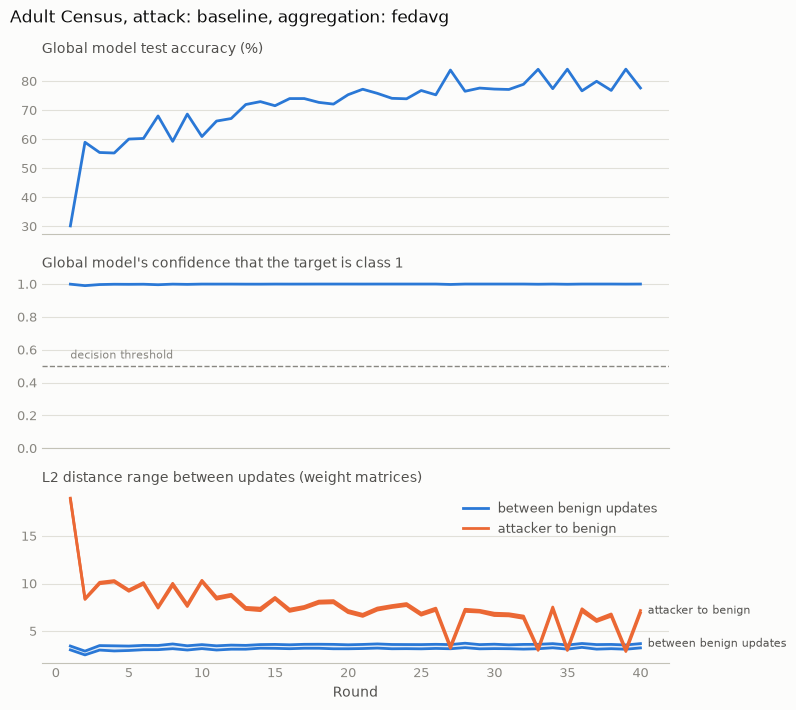

In [ ]:
# Per-round results: a table, then plots of test accuracy, the target's confidence and (under attack)
# the paper's L2 distance ranges and weight-update histograms. Colors: dataviz reference palette (light),
# checked for colour-blind safety
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

target_label = 1 - target_true_class
results = pd.DataFrame([(float(acc), float(conf), int(pred)) for acc, conf, pred in history],
                       columns=["test_acc", "target_conf", "predicted_class"])
results.index = pd.RangeIndex(1, len(results) + 1, name="round")
if attack:
    stealth = [s or {} for s in stealth_log]  # None when the attacker wasn't selected that round
    results["acc_attacker_model"] = [s.get("acc_mal", float("nan")) for s in stealth]
    results["acc_others"] = [s.get("acc_others", float("nan")) for s in stealth]
    results["passes_acc_check"] = [s.get("passes_accuracy_check") for s in stealth]
    for name, key in [("benign_l2", "benign_range"), ("attacker_l2", "mal_range")]:
        lows, highs = zip(*[s.get(key, (float("nan"), float("nan"))) for s in stealth])
        results[f"{name}_min"], results[f"{name}_max"] = lows, highs
display(results.round(4))

SURFACE, TEXT, TEXT_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"

panels = 3 if attack else 2
fig, axes = plt.subplots(panels, 1, figsize=(8, 2.4 * panels), sharex=True, facecolor=SURFACE)
setup = f"attack: {attack_type}" if attack else "no attack"
fig.suptitle(f"Adult Census, {setup}, aggregation: {aggregation}", color=TEXT, x=0.01, ha="left", fontsize=12)

ax = axes[0]
ax.plot(results.index, results.test_acc * 100, color=BLUE, lw=2)
ax.set_title("Global model test accuracy (%)", loc="left", color=TEXT_2, fontsize=10)

ax = axes[1]
ax.plot(results.index, results.target_conf, color=BLUE, lw=2)
ax.axhline(0.5, color=MUTED, lw=1, ls="--")
ax.text(results.index[0], 0.53, "decision threshold", color=MUTED, fontsize=8, va="bottom")
ax.set_ylim(0, 1.05)
ax.set_title(f"Global model's confidence that the target is class {target_label}", loc="left", color=TEXT_2, fontsize=10)

if attack:
    ax = axes[2]
    for name, color, label in [("benign_l2", BLUE, "between benign updates"), ("attacker_l2", ORANGE, "attacker to benign")]:
        ax.fill_between(results.index, results[f"{name}_min"], results[f"{name}_max"], color=color, alpha=0.1, lw=0)
        ax.plot(results.index, results[f"{name}_min"], color=color, lw=2, label=label)
        ax.plot(results.index, results[f"{name}_max"], color=color, lw=2)
        ax.text(results.index[-1] + 0.5, results[f"{name}_max"].iloc[-1], label, color=TEXT_2, fontsize=8, va="center")
    ax.legend(frameon=False, labelcolor=TEXT_2, fontsize=9, loc="upper right")
    ax.set_title("L2 distance range between updates (weight matrices)", loc="left", color=TEXT_2, fontsize=10)

for ax in axes:
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
axes[-1].set_xlabel("Round", color=TEXT_2)
fig.tight_layout()
plt.show()

# Weight-update value distributions, benign vs. attacker, in one round (the paper's histograms, e.g. its Fig. 8b/d/f)
if attack and stealth[-1]:
    hist_round = len(results)  # last round; change to look at another one
    s = stealth[hist_round - 1]
    lo, hi = -0.2, 0.2          # the paper's x-range
    bins = np.linspace(lo, hi, 121)
    fig2, ax = plt.subplots(figsize=(8, 3), facecolor=SURFACE)
    for key, color, label in [("benign_delta", BLUE, "benign client"), ("mal_delta", ORANGE, "attacker")]:
        values = s[key]
        outside = np.mean((values < lo) | (values > hi))
        ax.hist(values, bins=bins, histtype="stepfilled", color=color, alpha=0.15, lw=0)
        ax.hist(values, bins=bins, histtype="step", color=color, lw=1.5,
                label=f"{label} ({outside:.1%} of values outside ±0.2)")
    ax.legend(frameon=False, labelcolor=TEXT_2, fontsize=9, loc="upper right")
    ax.set_title(f"Weight-update values in round {hist_round} (weight matrices)", loc="left", color=TEXT_2, fontsize=10)
    ax.set_xlabel("Update value", color=TEXT_2)
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    fig2.tight_layout()
    plt.show()

In [ ]:


# # Make predictions with the best model
# Y_pred = best_model.predict(X_test)
# accuracy = accuracy_score(y_test, Y_pred)
# precision = precision_score(y_test, Y_pred, average="weighted")
# recall = recall_score(y_test, Y_pred, average="weighted")
# f1 = f1_score(y_test, Y_pred, average="weighted")

# # Print the evaluation metrics for the best model
# print(f"Accuracy: {accuracy}")
# print(f"Precision: {precision}, Recall: {recall}, F1 Score: {f1}")

